In [1]:
# ============================================================
# NOTEBOOK 10 — STRUCTURE AUDIT
# ============================================================
# Purpose:
#   Inspect the existing notebook before making any changes.
#   This prevents us from duplicating analysis already completed
#   in Notebook 09.
# ============================================================

from pathlib import Path
import json

PROJECT_ROOT = Path.cwd().parent
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "10_Explainability_and_Risk_Mapping.ipynb"

print("=" * 70)
print("NOTEBOOK 10 — STRUCTURE AUDIT")
print("=" * 70)

print(f"\nProject root:")
print(PROJECT_ROOT)

print(f"\nNotebook path:")
print(NOTEBOOK_PATH)

print(f"\nNotebook exists: {NOTEBOOK_PATH.exists()}")

if NOTEBOOK_PATH.exists():
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    markdown_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "markdown"
    ]

    code_cells = [
        cell for cell in cells
        if cell.get("cell_type") == "code"
    ]

    print(f"\nTotal cells: {len(cells)}")
    print(f"Markdown cells: {len(markdown_cells)}")
    print(f"Code cells: {len(code_cells)}")

    print("\n" + "=" * 70)
    print("NOTEBOOK SECTIONS")
    print("=" * 70)

    for i, cell in enumerate(cells, start=1):
        source = "".join(cell.get("source", [])).strip()

        if cell.get("cell_type") == "markdown":
            headings = [
                line.strip()
                for line in source.splitlines()
                if line.strip().startswith("#")
            ]

            if headings:
                print(f"\nCell {i}:")
                for heading in headings:
                    print(heading)

    print("\n" + "=" * 70)
    print("CODE CELL SUMMARY")
    print("=" * 70)

    for i, cell in enumerate(cells, start=1):
        if cell.get("cell_type") == "code":
            source = "".join(cell.get("source", [])).strip()

            first_lines = source.splitlines()[:3]

            print(f"\nCode Cell {i}:")
            for line in first_lines:
                print(line[:120])

else:
    print("\nERROR: Notebook 10 was not found.")

NOTEBOOK 10 — STRUCTURE AUDIT

Project root:
c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria

Notebook path:
c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\notebooks\10_Explainability_and_Risk_Mapping.ipynb

Notebook exists: True

Total cells: 3
Markdown cells: 2
Code cells: 1

NOTEBOOK SECTIONS

Cell 1:
# Explainability and Risk Mapping
## Machine Learning-Based Early Warning System for Poultry Disease Outbreaks in Nigeria

Cell 2:
## Status

CODE CELL SUMMARY

Code Cell 3:
from pathlib import Path
import pandas as pd



In [2]:
# ============================================================
# NOTEBOOK 10 — EXPLAINABILITY AND RISK MAPPING
# ============================================================
# Purpose:
#   Prepare the final model, evaluation artefacts and
#   administrative surveillance data for interpretability
#   and historical geographic risk/activity analysis.
#
# Important distinction:
#   This notebook does NOT claim to produce a clinically
#   validated geographic disease-risk prediction.
#
#   Geographic outputs describe historical reported outbreak
#   activity in the available surveillance data and are used
#   for decision-support interpretation.
# ============================================================

from pathlib import Path
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
EVALUATION_DIR = ARTIFACTS_DIR / "evaluation"
FINAL_MODEL_DIR = ARTIFACTS_DIR / "final_model"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"


# ------------------------------------------------------------
# 2. Add project source directory
# ------------------------------------------------------------

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# ------------------------------------------------------------
# 3. Define required artefacts
# ------------------------------------------------------------

required_files = {
    "model": FINAL_MODEL_DIR / "random_forest_pipeline.joblib",
    "metadata": FINAL_MODEL_DIR / "model_metadata.json",
    "production_schema": FINAL_MODEL_DIR / "production_schema.json",
    "evaluation_summary": EVALUATION_DIR / "rolling_origin_evaluation_summary.json",
    "fold_metrics": EVALUATION_DIR / "rolling_origin_fold_metrics.csv",
    "oos_predictions": EVALUATION_DIR / "rolling_origin_oos_predictions.csv",
    "feature_importance": EVALUATION_DIR / "random_forest_feature_importance.csv",
    "oos_permutation_importance": EVALUATION_DIR / "random_forest_oos_permutation_importance.csv",
    "administrative_data": PROCESSED_DATA_DIR / "wahis_analytical_table.csv",
}


# ------------------------------------------------------------
# 4. Verify artefacts
# ------------------------------------------------------------

print("=" * 70)
print("NOTEBOOK 10 — ARTEFACT AND DATA PREPARATION")
print("=" * 70)

for name, path in required_files.items():
    print(f"{name:30s}: {path.exists()}")

missing_files = [
    name for name, path in required_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required artefacts/data files: "
        + ", ".join(missing_files)
    )


# ------------------------------------------------------------
# 5. Load metadata and evaluation results
# ------------------------------------------------------------

with open(required_files["metadata"], "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

with open(required_files["production_schema"], "r", encoding="utf-8") as f:
    production_schema = json.load(f)

with open(required_files["evaluation_summary"], "r", encoding="utf-8") as f:
    evaluation_summary = json.load(f)


fold_metrics_df = pd.read_csv(required_files["fold_metrics"])
oos_predictions_df = pd.read_csv(required_files["oos_predictions"])
feature_importance_df = pd.read_csv(required_files["feature_importance"])
oos_permutation_importance_df = pd.read_csv(
    required_files["oos_permutation_importance"]
)

administrative_df = pd.read_csv(required_files["administrative_data"])


# ------------------------------------------------------------
# 6. Basic validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADED DATASETS")
print("=" * 70)

print(f"\nAdministrative analytical table shape: {administrative_df.shape}")
print(f"Out-of-sample predictions shape: {oos_predictions_df.shape}")
print(f"Fold metrics shape: {fold_metrics_df.shape}")
print(f"Feature importance shape: {feature_importance_df.shape}")
print(
    "OOS permutation importance shape: "
    f"{oos_permutation_importance_df.shape}"
)

print("\nSelected model:")
print(model_metadata["model_name"])

print("\nTarget:")
print(model_metadata["target_column"])

print("\nValidation method:")
print(evaluation_summary["evaluation_method"])

print("\nValidation folds:")
print(evaluation_summary["validation_folds"])

print("\nPooled OOS MAE:")
print(round(evaluation_summary["pooled_mae"], 3))

print("\nPooled OOS RMSE:")
print(round(evaluation_summary["pooled_rmse"], 3))

print("\nMean fold MAE:")
print(round(evaluation_summary["mean_fold_mae"], 3))

print("\nMean fold RMSE:")
print(round(evaluation_summary["mean_fold_rmse"], 3))


# ------------------------------------------------------------
# 7. Validate the key model feature set
# ------------------------------------------------------------

model_features = model_metadata["features"]

schema_features = production_schema["features"]["ordered_names"]

assert model_features == schema_features, (
    "Model metadata features and production schema features differ."
)

assert len(model_features) == 27, (
    f"Expected 27 model features, found {len(model_features)}."
)

print("\nModel feature count:")
print(len(model_features))

print("\nMODEL 10 PREPARATION: PASSED")

NOTEBOOK 10 — ARTEFACT AND DATA PREPARATION
model                         : True
metadata                      : True
production_schema             : True
evaluation_summary            : True
fold_metrics                  : True
oos_predictions               : True
feature_importance            : True
oos_permutation_importance    : True
administrative_data           : True

LOADED DATASETS

Administrative analytical table shape: (1180, 22)
Out-of-sample predictions shape: (302, 4)
Fold metrics shape: (8, 7)
Feature importance shape: (27, 2)
OOS permutation importance shape: (27, 3)

Selected model:
Random Forest

Target:
target_outbreak_count

Validation method:
rolling_origin_temporal_validation

Validation folds:
8

Pooled OOS MAE:
6.415

Pooled OOS RMSE:
13.207

Mean fold MAE:
6.515

Mean fold RMSE:
11.594

Model feature count:
27

MODEL 10 PREPARATION: PASSED


## 2. Model Explainability

This section summarises which predictor variables contributed most strongly
to the Random Forest model's predictions.

Two complementary sources of importance are considered:

1. **Impurity-based feature importance**
   - Measures the contribution of features within the fitted Random Forest.
   - Useful for understanding how the final model was constructed.

2. **Out-of-sample permutation importance**
   - Measures the change in predictive performance when a feature is
     randomly permuted during out-of-sample evaluation.
   - Provides a more evaluation-oriented view of feature usefulness.

The out-of-sample permutation results are given greater interpretive
importance because they are based on the model's chronological
out-of-sample predictions.

Feature importance is interpreted as model association/contribution,
not as evidence of causality.

In [3]:
# ============================================================
# 2. MODEL EXPLAINABILITY — FEATURE IMPORTANCE
# ============================================================

print("=" * 70)
print("MODEL EXPLAINABILITY — FEATURE IMPORTANCE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Prepare impurity-based feature importance
# ------------------------------------------------------------

impurity_df = feature_importance_df.copy()

impurity_df = impurity_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. Prepare out-of-sample permutation importance
# ------------------------------------------------------------

permutation_df = oos_permutation_importance_df.copy()

permutation_df = permutation_df.sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Display top features
# ------------------------------------------------------------

print("\nTop 15 impurity-based features:")
display(
    impurity_df.head(15)
)


print("\nTop 15 out-of-sample permutation features:")
display(
    permutation_df.head(15)
)


# ------------------------------------------------------------
# 4. Identify dominant features
# ------------------------------------------------------------

top_impurity_features = impurity_df.head(10)["feature"].tolist()

top_permutation_features = (
    permutation_df.head(10)["feature"].tolist()
)


print("\nTop 10 impurity-based features:")
for i, feature in enumerate(top_impurity_features, start=1):
    print(f"{i:2d}. {feature}")


print("\nTop 10 out-of-sample permutation features:")
for i, feature in enumerate(top_permutation_features, start=1):
    print(f"{i:2d}. {feature}")


# ------------------------------------------------------------
# 5. Sanity checks
# ------------------------------------------------------------

assert len(impurity_df) == 27, (
    f"Expected 27 impurity importance rows, found {len(impurity_df)}."
)

assert len(permutation_df) == 27, (
    f"Expected 27 permutation importance rows, found {len(permutation_df)}."
)

assert set(impurity_df["feature"]) == set(model_features), (
    "Impurity importance features do not match model feature set."
)

assert set(permutation_df["feature"]) == set(model_features), (
    "Permutation importance features do not match model feature set."
)


print("\nEXPLAINABILITY FEATURE TABLES: PASSED")

MODEL EXPLAINABILITY — FEATURE IMPORTANCE

Top 15 impurity-based features:


,feature,importance
0,previous_semester_outbreak_count,0.288021
1,outbreak_history_max_3,0.144318
2,outbreak_history_mean_3,0.140401
3,semester_total_precipitation_mm,0.090721
4,year_sin,0.045698
5,two_semesters_prior_outbreak_count,0.041700
6,year,0.041101
7,years_since_2019,0.041081
8,semester_mean_wind_component_magnitude_ms,0.040506
9,dewpoint_c,0.039398



Top 15 out-of-sample permutation features:


,feature,importance_mean,importance_std
0,previous_semester_outbreak_count,1.221816,0.814057
1,outbreak_history_mean_3,1.206102,0.671723
2,outbreak_history_max_3,1.090675,0.660638
3,two_semesters_prior_outbreak_count,0.165297,0.120262
4,semester_total_precipitation_mm,0.109424,0.115832
5,disease_code,0.075869,0.100094
6,dewpoint_c,0.072373,0.087558
7,semester_mean_wind_component_magnitude_ms,0.041339,0.135901
8,climate_variable_count,0.000000,0.000000
9,climate_available,0.000000,0.000000



Top 10 impurity-based features:
 1. previous_semester_outbreak_count
 2. outbreak_history_max_3
 3. outbreak_history_mean_3
 4. semester_total_precipitation_mm
 5. year_sin
 6. two_semesters_prior_outbreak_count
 7. year
 8. years_since_2019
 9. semester_mean_wind_component_magnitude_ms
10. dewpoint_c

Top 10 out-of-sample permutation features:
 1. previous_semester_outbreak_count
 2. outbreak_history_mean_3
 3. outbreak_history_max_3
 4. two_semesters_prior_outbreak_count
 5. semester_total_precipitation_mm
 6. disease_code
 7. dewpoint_c
 8. semester_mean_wind_component_magnitude_ms
 9. climate_variable_count
10. climate_available

EXPLAINABILITY FEATURE TABLES: PASSED


## 3. Explainability Visualisation

The following visualisation compares the two feature-importance approaches.

The out-of-sample permutation importance is emphasised because it evaluates
feature usefulness using chronological out-of-sample predictions.

Positive permutation importance indicates that permuting the feature
generally worsened predictive performance.

Feature importance should not be interpreted as causal evidence. In
particular, the strong contribution of previous outbreak history indicates
that the model relies heavily on temporal persistence in reported outbreak
activity.

EXPLAINABILITY VISUALISATION


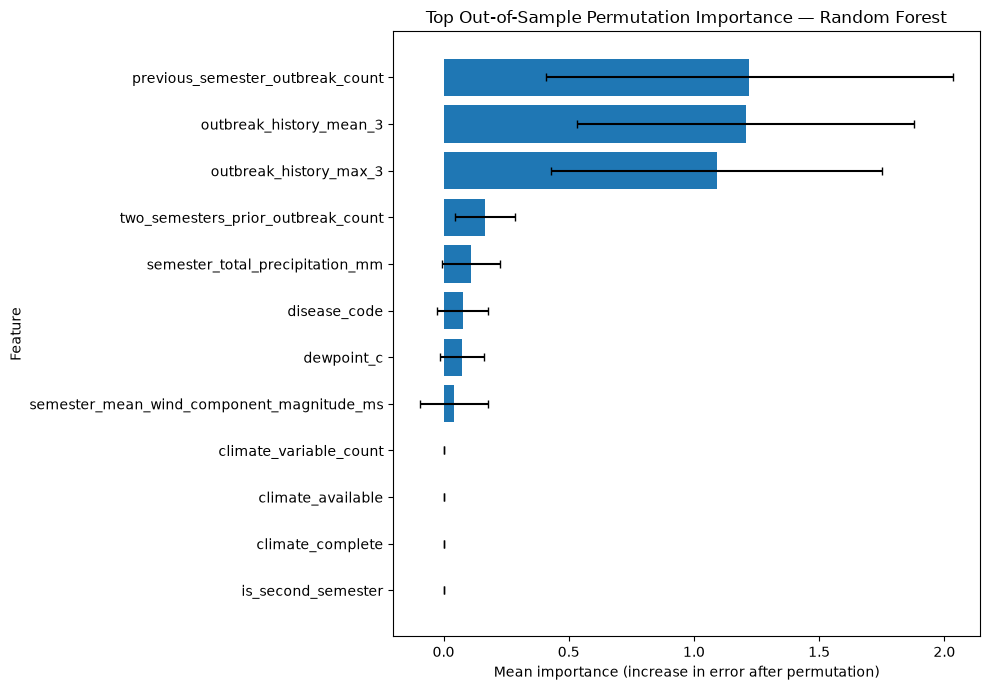


Top 12 out-of-sample permutation features:


,feature,importance_mean,importance_std
0,previous_semester_outbreak_count,1.221816,0.814057
1,outbreak_history_mean_3,1.206102,0.671723
2,outbreak_history_max_3,1.090675,0.660638
3,two_semesters_prior_outbreak_count,0.165297,0.120262
4,semester_total_precipitation_mm,0.109424,0.115832
5,disease_code,0.075869,0.100094
6,dewpoint_c,0.072373,0.087558
7,semester_mean_wind_component_magnitude_ms,0.041339,0.135901
8,climate_variable_count,0.000000,0.000000
9,climate_available,0.000000,0.000000



EXPLAINABILITY VISUALISATION: PASSED


In [4]:
# ============================================================
# 3. EXPLAINABILITY VISUALISATION
# ============================================================

print("=" * 70)
print("EXPLAINABILITY VISUALISATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Select top features
# ------------------------------------------------------------

plot_df = permutation_df.head(12).copy()

plot_df = plot_df.sort_values(
    "importance_mean",
    ascending=True
)


# ------------------------------------------------------------
# 2. Plot out-of-sample permutation importance
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_df["feature"],
    plot_df["importance_mean"],
    xerr=plot_df["importance_std"],
    capsize=3
)

ax.set_title(
    "Top Out-of-Sample Permutation Importance — Random Forest"
)

ax.set_xlabel(
    "Mean importance (increase in error after permutation)"
)

ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Print interpretation-ready table
# ------------------------------------------------------------

print("\nTop 12 out-of-sample permutation features:")

display(
    permutation_df[
        ["feature", "importance_mean", "importance_std"]
    ].head(12)
)


print("\nEXPLAINABILITY VISUALISATION: PASSED")

## 4. Historical Geographic Surveillance Activity

This section examines the geographic structure of the WAHIS analytical
dataset and summarises reported outbreak activity by available
administrative level.

The geographic analysis is descriptive and surveillance-oriented.

It does NOT represent a geographically resolved prediction of future
disease risk unless the model explicitly produces predictions at that
geographic level.

The purpose is to identify where reported outbreak activity is
concentrated in the available historical surveillance data and to
support interpretation of the early-warning system.

In [5]:
# ============================================================
# 4. HISTORICAL GEOGRAPHIC SURVEILLANCE ACTIVITY
# ============================================================

print("=" * 70)
print("HISTORICAL GEOGRAPHIC SURVEILLANCE ACTIVITY")
print("=" * 70)


# ------------------------------------------------------------
# 1. Inspect available columns
# ------------------------------------------------------------

print("\nAdministrative analytical table columns:")
for i, column in enumerate(administrative_df.columns, start=1):
    print(f"{i:2d}. {column}")


# ------------------------------------------------------------
# 2. Identify geographic-related columns
# ------------------------------------------------------------

geographic_keywords = [
    "admin",
    "adm",
    "country",
    "region",
    "state",
    "province",
    "district",
    "location",
    "latitude",
    "longitude",
    "lat",
    "lon",
    "geo"
]

geographic_columns = [
    column
    for column in administrative_df.columns
    if any(keyword in column.lower() for keyword in geographic_keywords)
]

print("\nPotential geographic columns:")
for column in geographic_columns:
    print(f"- {column}")


# ------------------------------------------------------------
# 3. Show data types
# ------------------------------------------------------------

print("\nData types of potential geographic columns:")

display(
    administrative_df[geographic_columns].dtypes.to_frame(
        name="dtype"
    )
)


# ------------------------------------------------------------
# 4. Show a sample of geographic fields
# ------------------------------------------------------------

print("\nSample geographic records:")

display(
    administrative_df[geographic_columns].head(10)
)


# ------------------------------------------------------------
# 5. Basic geographic completeness
# ------------------------------------------------------------

geographic_completeness = pd.DataFrame({
    "column": geographic_columns,
    "non_null_count": [
        administrative_df[column].notna().sum()
        for column in geographic_columns
    ],
    "missing_count": [
        administrative_df[column].isna().sum()
        for column in geographic_columns
    ],
    "unique_values": [
        administrative_df[column].nunique(dropna=True)
        for column in geographic_columns
    ]
})

print("\nGeographic field completeness:")

display(
    geographic_completeness.sort_values(
        "non_null_count",
        ascending=False
    )
)


print("\nGEOGRAPHIC STRUCTURE INSPECTION: PASSED")

HISTORICAL GEOGRAPHIC SURVEILLANCE ACTIVITY

Administrative analytical table columns:
 1. analytical_record_id
 2. year
 3. semester
 4. country
 5. world_region
 6. administrative_division
 7. disease
 8. animal_category
 9. species
10. new_outbreaks
11. outbreak_count_observed
12. outbreak_observation_status
13. serotype_subtype_genotype
14. event_id
15. outbreak_id
16. susceptible
17. measuring_units
18. cases
19. killed_and_disposed_of
20. slaughtered
21. deaths
22. vaccinated

Potential geographic columns:
- country
- world_region
- administrative_division

Data types of potential geographic columns:


,dtype
country,object
world_region,object
administrative_division,object



Sample geographic records:


,country,world_region,administrative_division
0,Nigeria,Africa,Nigeria
1,Nigeria,Africa,Nigeria
2,Nigeria,Africa,Nigeria
3,Nigeria,Africa,Nigeria
4,Nigeria,Africa,Nigeria
5,Nigeria,Africa,Gombe
6,Nigeria,Africa,Adamawa
7,Nigeria,Africa,Bauchi
8,Nigeria,Africa,Bauchi
9,Nigeria,Africa,Delta



Geographic field completeness:


,column,non_null_count,missing_count,unique_values
0,country,1180,0,1
1,world_region,1180,0,1
2,administrative_division,1179,1,39



GEOGRAPHIC STRUCTURE INSPECTION: PASSED


## 5. State-Level Historical Outbreak Activity

The analytical table contains 39 administrative divisions, corresponding
to state-level or equivalent administrative reporting units in Nigeria.

This section aggregates historical reported outbreak activity by
administrative division.

The analysis considers:

- number of analytical records;
- total observed outbreak counts;
- total reported new outbreaks;
- total cases;
- total deaths;
- total animals killed/disposed of;
- total animals slaughtered.

These summaries describe historical surveillance activity in the dataset.
They should not be interpreted as estimates of true disease prevalence
because surveillance coverage, reporting completeness and outbreak
detection may vary geographically and over time.

In [6]:
# ============================================================
# 5. STATE-LEVEL HISTORICAL OUTBREAK ACTIVITY
# ============================================================

print("=" * 70)
print("STATE-LEVEL HISTORICAL OUTBREAK ACTIVITY")
print("=" * 70)


# ------------------------------------------------------------
# 1. Work with records that have an administrative division
# ------------------------------------------------------------

geo_df = administrative_df[
    administrative_df["administrative_division"].notna()
].copy()

print(f"\nRecords with administrative division: {len(geo_df)}")
print(
    "Unique administrative divisions:",
    geo_df["administrative_division"].nunique()
)


# ------------------------------------------------------------
# 2. Ensure quantitative fields are numeric
# ------------------------------------------------------------

numeric_activity_columns = [
    "new_outbreaks",
    "outbreak_count_observed",
    "cases",
    "deaths",
    "killed_and_disposed_of",
    "slaughtered",
    "vaccinated",
    "susceptible"
]

for column in numeric_activity_columns:
    geo_df[column] = pd.to_numeric(
        geo_df[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 3. Aggregate historical activity by administrative division
# ------------------------------------------------------------

state_activity = (
    geo_df
    .groupby("administrative_division", dropna=False)
    .agg(
        analytical_records=("analytical_record_id", "count"),
        total_observed_outbreaks=(
            "outbreak_count_observed",
            "sum"
        ),
        total_new_outbreaks=(
            "new_outbreaks",
            "sum"
        ),
        total_cases=("cases", "sum"),
        total_deaths=("deaths", "sum"),
        total_killed_disposed=(
            "killed_and_disposed_of",
            "sum"
        ),
        total_slaughtered=("slaughtered", "sum"),
        total_vaccinated=("vaccinated", "sum")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 4. Rank by observed outbreak activity
# ------------------------------------------------------------

state_activity = state_activity.sort_values(
    "total_observed_outbreaks",
    ascending=False
).reset_index(drop=True)


state_activity["activity_rank"] = (
    state_activity.index + 1
)


# ------------------------------------------------------------
# 5. Display the complete ranking
# ------------------------------------------------------------

print("\nAdministrative divisions ranked by total observed outbreak count:")

display(
    state_activity[
        [
            "activity_rank",
            "administrative_division",
            "analytical_records",
            "total_observed_outbreaks",
            "total_new_outbreaks",
            "total_cases",
            "total_deaths"
        ]
    ]
)


# ------------------------------------------------------------
# 6. Summary statistics
# ------------------------------------------------------------

print("\nHistorical activity summary:")
print(
    f"Administrative divisions represented: "
    f"{state_activity['administrative_division'].nunique()}"
)

print(
    f"Total observed outbreaks: "
    f"{state_activity['total_observed_outbreaks'].sum():,.0f}"
)

print(
    f"Total reported new outbreaks: "
    f"{state_activity['total_new_outbreaks'].sum():,.0f}"
)

print(
    f"Total reported cases: "
    f"{state_activity['total_cases'].sum():,.0f}"
)

print(
    f"Total reported deaths: "
    f"{state_activity['total_deaths'].sum():,.0f}"
)


# ------------------------------------------------------------
# 7. Validate aggregation
# ------------------------------------------------------------

assert state_activity["administrative_division"].nunique() == 39

assert (
    state_activity["total_observed_outbreaks"].sum()
    == geo_df["outbreak_count_observed"].sum()
)

print("\nSTATE-LEVEL ACTIVITY AGGREGATION: PASSED")

STATE-LEVEL HISTORICAL OUTBREAK ACTIVITY

Records with administrative division: 1179
Unique administrative divisions: 39

Administrative divisions ranked by total observed outbreak count:


,activity_rank,administrative_division,analytical_records,total_observed_outbreaks,total_new_outbreaks,total_cases,total_deaths
0,1,Jigawa,66,29,290.0,96610.0,18761.0
1,2,Kaduna,65,24,179.0,23079.0,4499.0
2,3,Kogi,46,21,96.0,25650.0,1406.0
3,4,Osun,70,21,177.0,26814.0,5831.0
4,5,Akwa Ibom,42,19,734.0,1919747.0,386391.0
5,6,Benue,43,18,243.0,36644.0,3076.0
6,7,Bayelsa,38,17,64.0,250148.0,6516.0
7,8,Kwara,52,17,85.0,196226.0,11079.0
8,9,Niger,45,17,71.0,11568.0,3132.0
9,10,Gombe,50,17,28.0,64087.0,2084.0



Historical activity summary:
Administrative divisions represented: 39
Total observed outbreaks: 444
Total reported new outbreaks: 3,043
Total reported cases: 3,251,618
Total reported deaths: 538,320

STATE-LEVEL ACTIVITY AGGREGATION: PASSED


## 6. Geographic Data Quality and State-Level Activity Analysis

Before interpreting administrative patterns, geographic labels are checked
for country-level records and possible spelling inconsistencies.

Country-level records are excluded from state-level analysis.

Where two labels appear to represent the same administrative unit, the
standardisation is applied only to the geographic analysis dataset and does
not modify the source analytical table.

State-level activity is then examined alongside the number of analytical
records to provide context for differences in reported activity.

In [8]:
# ============================================================
# 6. GEOGRAPHIC DATA QUALITY AND STATE-LEVEL ANALYSIS
# ============================================================

print("=" * 70)
print("GEOGRAPHIC DATA QUALITY AND STATE-LEVEL ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Inspect administrative labels
# ------------------------------------------------------------

admin_labels = sorted(
    geo_df["administrative_division"]
    .dropna()
    .astype(str)
    .unique()
)

print("\nAdministrative labels:")
for label in admin_labels:
    print(f"- {label}")


# ------------------------------------------------------------
# 2. Identify country-level administrative records
# ------------------------------------------------------------

country_level_mask = (
    geo_df["administrative_division"].str.strip().str.lower()
    == geo_df["country"].str.strip().str.lower()
)

country_level_records = geo_df[country_level_mask].copy()

print(
    "\nCountry-level records found:",
    len(country_level_records)
)

if len(country_level_records) > 0:
    print(
        "Country-level labels:",
        country_level_records[
            "administrative_division"
        ].unique().tolist()
    )


# ------------------------------------------------------------
# 3. Create state-level analysis dataset
# ------------------------------------------------------------

state_geo_df = geo_df.loc[
    ~country_level_mask
].copy()


# ------------------------------------------------------------
# 4. Standardise the apparent Nasarawa spelling variant
# ------------------------------------------------------------

state_geo_df["administrative_division"] = (
    state_geo_df["administrative_division"]
    .astype(str)
    .str.strip()
    .replace({
        "Nassarawa": "Nasarawa"
    })
)


# ------------------------------------------------------------
# 5. Recalculate state-level activity
# ------------------------------------------------------------

state_activity_clean = (
    state_geo_df
    .groupby("administrative_division")
    .agg(
        analytical_records=("analytical_record_id", "count"),
        total_observed_outbreaks=(
            "outbreak_count_observed",
            "sum"
        ),
        total_new_outbreaks=(
            "new_outbreaks",
            "sum"
        ),
        total_cases=("cases", "sum"),
        total_deaths=("deaths", "sum")
    )
    .reset_index()
)


state_activity_clean = state_activity_clean.sort_values(
    "total_observed_outbreaks",
    ascending=False
).reset_index(drop=True)

state_activity_clean["activity_rank"] = (
    state_activity_clean.index + 1
)


# ------------------------------------------------------------
# 6. Display cleaned state-level ranking
# ------------------------------------------------------------

print("\nCleaned state-level activity ranking:")

display(
    state_activity_clean[
        [
            "activity_rank",
            "administrative_division",
            "analytical_records",
            "total_observed_outbreaks",
            "total_new_outbreaks",
            "total_cases",
            "total_deaths"
        ]
    ]
)


# ------------------------------------------------------------
# 7. Validate geographic structure
# ------------------------------------------------------------

print(
    "\nState-level administrative divisions:",
    state_activity_clean["administrative_division"].nunique()
)

print(
    "State-level records:",
    len(state_geo_df)
)

print(
    "Country-level records excluded:",
    len(country_level_records)
)


assert "Nigeria" not in (
    state_activity_clean["administrative_division"].tolist()
)

assert (
    state_activity_clean["administrative_division"].nunique()
    == 37
)

print("\nGEOGRAPHIC DATA QUALITY CHECK: PASSED")

GEOGRAPHIC DATA QUALITY AND STATE-LEVEL ANALYSIS

Administrative labels:
- Abia
- Adamawa
- Akwa Ibom
- Anambra
- Bauchi
- Bayelsa
- Benue
- Borno
- Cross River
- Delta
- Ebonyi
- Edo
- Ekiti
- Enugu
- Federal Capital Territory
- Gombe
- Imo
- Jigawa
- Kaduna
- Kano
- Katsina
- Kebbi
- Kogi
- Kwara
- Lagos
- Nasarawa
- Nassarawa
- Niger
- Nigeria
- Ogun
- Ondo
- Osun
- Oyo
- Plateau
- Rivers
- Sokoto
- Taraba
- Yobe
- Zamfara

Country-level records found: 5
Country-level labels: ['Nigeria']

Cleaned state-level activity ranking:


,activity_rank,administrative_division,analytical_records,total_observed_outbreaks,total_new_outbreaks,total_cases,total_deaths
0,1,Jigawa,66,29,290.0,96610.0,18761.0
1,2,Kaduna,65,24,179.0,23079.0,4499.0
2,3,Osun,70,21,177.0,26814.0,5831.0
3,4,Kogi,46,21,96.0,25650.0,1406.0
4,5,Akwa Ibom,42,19,734.0,1919747.0,386391.0
5,6,Benue,43,18,243.0,36644.0,3076.0
6,7,Niger,45,17,71.0,11568.0,3132.0
7,8,Gombe,50,17,28.0,64087.0,2084.0
8,9,Bayelsa,38,17,64.0,250148.0,6516.0
9,10,Kwara,52,17,85.0,196226.0,11079.0



State-level administrative divisions: 37
State-level records: 1174
Country-level records excluded: 5

GEOGRAPHIC DATA QUALITY CHECK: PASSED


## 7. Temporal and Geographic Patterns

This section examines how reported outbreak activity varies across
administrative divisions and over time.

The analysis is descriptive. It is intended to identify historical
surveillance patterns that may be useful when interpreting the early
warning model.

Higher reported activity in a particular administrative division does
not necessarily indicate higher underlying disease risk, because observed
surveillance activity may also reflect differences in reporting,
surveillance coverage, outbreak detection and the number of records
available for that location.

In [9]:
# ============================================================
# 7. TEMPORAL AND GEOGRAPHIC PATTERNS
# ============================================================

print("=" * 70)
print("TEMPORAL AND GEOGRAPHIC PATTERNS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Aggregate activity by year and administrative division
# ------------------------------------------------------------

state_year_activity = (
    state_geo_df
    .groupby(
        ["year", "administrative_division"],
        as_index=False
    )
    .agg(
        analytical_records=("analytical_record_id", "count"),
        observed_outbreaks=(
            "outbreak_count_observed",
            "sum"
        ),
        new_outbreaks=("new_outbreaks", "sum"),
        cases=("cases", "sum"),
        deaths=("deaths", "sum")
    )
)

state_year_activity["administrative_division"] = (
    state_year_activity["administrative_division"]
    .astype(str)
    .str.strip()
    .replace({"Nassarawa": "Nasarawa"})
)


# ------------------------------------------------------------
# 2. Aggregate national activity by year
# ------------------------------------------------------------

national_year_activity = (
    state_geo_df
    .groupby("year", as_index=False)
    .agg(
        analytical_records=("analytical_record_id", "count"),
        observed_outbreaks=(
            "outbreak_count_observed",
            "sum"
        ),
        new_outbreaks=("new_outbreaks", "sum"),
        cases=("cases", "sum"),
        deaths=("deaths", "sum")
    )
)

print("\nNational historical activity by year:")

display(national_year_activity)


# ------------------------------------------------------------
# 3. Identify the most active states by year
# ------------------------------------------------------------

top_states_by_year = (
    state_year_activity
    .sort_values(
        ["year", "observed_outbreaks"],
        ascending=[True, False]
    )
    .groupby("year")
    .head(5)
    .reset_index(drop=True)
)

print("\nTop 5 administrative divisions by observed outbreaks for each year:")

display(
    top_states_by_year[
        [
            "year",
            "administrative_division",
            "observed_outbreaks",
            "analytical_records",
            "new_outbreaks"
        ]
    ]
)


# ------------------------------------------------------------
# 4. Calculate each state's share of observed outbreaks
# ------------------------------------------------------------

state_totals = (
    state_geo_df
    .groupby("administrative_division", as_index=False)
    .agg(
        observed_outbreaks=(
            "outbreak_count_observed",
            "sum"
        ),
        analytical_records=("analytical_record_id", "count")
    )
)

total_observed_outbreaks = (
    state_totals["observed_outbreaks"].sum()
)

state_totals["share_of_observed_outbreaks_pct"] = (
    state_totals["observed_outbreaks"]
    / total_observed_outbreaks
    * 100
)

state_totals = state_totals.sort_values(
    "observed_outbreaks",
    ascending=False
).reset_index(drop=True)


print("\nState share of total observed outbreak activity:")

display(
    state_totals.head(15)
)


# ------------------------------------------------------------
# 5. Validation
# ------------------------------------------------------------

assert len(national_year_activity) > 0
assert state_year_activity["year"].notna().all()
assert state_year_activity[
    "administrative_division"
].notna().all()

assert np.isclose(
    state_totals["observed_outbreaks"].sum(),
    total_observed_outbreaks
)

print("\nTEMPORAL-GEOGRAPHIC ANALYSIS: PASSED")

TEMPORAL AND GEOGRAPHIC PATTERNS

National historical activity by year:


,year,analytical_records,observed_outbreaks,new_outbreaks,cases,deaths
0,2007,1,0,0.0,0.0,25.0
1,2008,42,0,0.0,39480.0,5905.0
2,2009,20,0,0.0,10916.0,3012.0
3,2010,15,0,0.0,2271.0,916.0
4,2011,15,0,0.0,3946.0,1672.0
5,2012,23,0,0.0,31216.0,10410.0
6,2013,16,0,0.0,2960.0,1079.0
7,2014,10,0,0.0,3272.0,1319.0
8,2015,12,0,0.0,1692.0,518.0
9,2016,4,0,0.0,93.0,20.0



Top 5 administrative divisions by observed outbreaks for each year:


,year,administrative_division,observed_outbreaks,analytical_records,new_outbreaks
0,2007,Gombe,0,1,0.0
1,2008,Adamawa,0,1,0.0
2,2008,Anambra,0,1,0.0
3,2008,Bauchi,0,3,0.0
4,2008,Delta,0,2,0.0
...,...,...,...,...,...
84,2025,Jigawa,6,12,118.0
85,2025,Kaduna,6,12,52.0
86,2025,Kogi,6,12,26.0
87,2025,Akwa Ibom,5,10,64.0



State share of total observed outbreak activity:


,administrative_division,observed_outbreaks,analytical_records,share_of_observed_outbreaks_pct
0,Jigawa,29,66,6.531532
1,Kaduna,24,65,5.405405
2,Osun,21,70,4.729730
3,Kogi,21,46,4.729730
4,Akwa Ibom,19,42,4.279279
5,Benue,18,43,4.054054
6,Niger,17,45,3.828829
7,Gombe,17,50,3.828829
8,Bayelsa,17,38,3.828829
9,Kwara,17,52,3.828829



TEMPORAL-GEOGRAPHIC ANALYSIS: PASSED


## 7.1 Temporal Trends in Reported Outbreak Activity

The following visualisations show how reported outbreak activity changed
over time at the national level and across administrative divisions.

These figures describe historical reported activity rather than predicted
future disease risk.

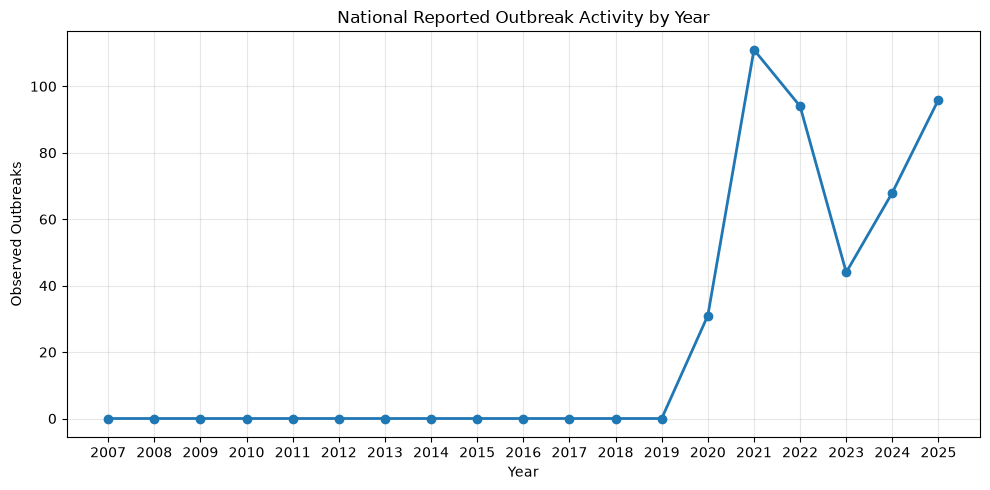

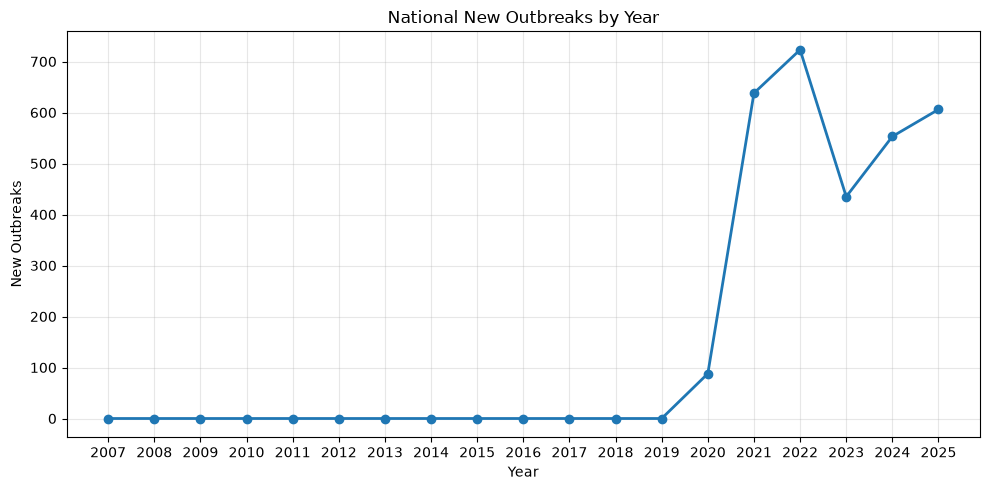

TEMPORAL TREND VISUALISATIONS: PASSED


In [10]:
# ============================================================
# 7.1 TEMPORAL TRENDS IN REPORTED OUTBREAK ACTIVITY
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# National observed outbreaks by year
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    national_year_activity["year"],
    national_year_activity["observed_outbreaks"],
    marker="o",
    linewidth=2
)

plt.title("National Reported Outbreak Activity by Year")
plt.xlabel("Year")
plt.ylabel("Observed Outbreaks")
plt.xticks(national_year_activity["year"])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# National new outbreaks by year
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    national_year_activity["year"],
    national_year_activity["new_outbreaks"],
    marker="o",
    linewidth=2
)

plt.title("National New Outbreaks by Year")
plt.xlabel("Year")
plt.ylabel("New Outbreaks")
plt.xticks(national_year_activity["year"])
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


print("TEMPORAL TREND VISUALISATIONS: PASSED")

## 7.2 Geographic Distribution of Historical Reported Activity

The next figure compares administrative divisions by the number of
observed outbreaks recorded in the analytical dataset.

The ranking should be interpreted as reported surveillance activity.
It should not be interpreted as a direct estimate of disease prevalence
or underlying epidemiological risk.

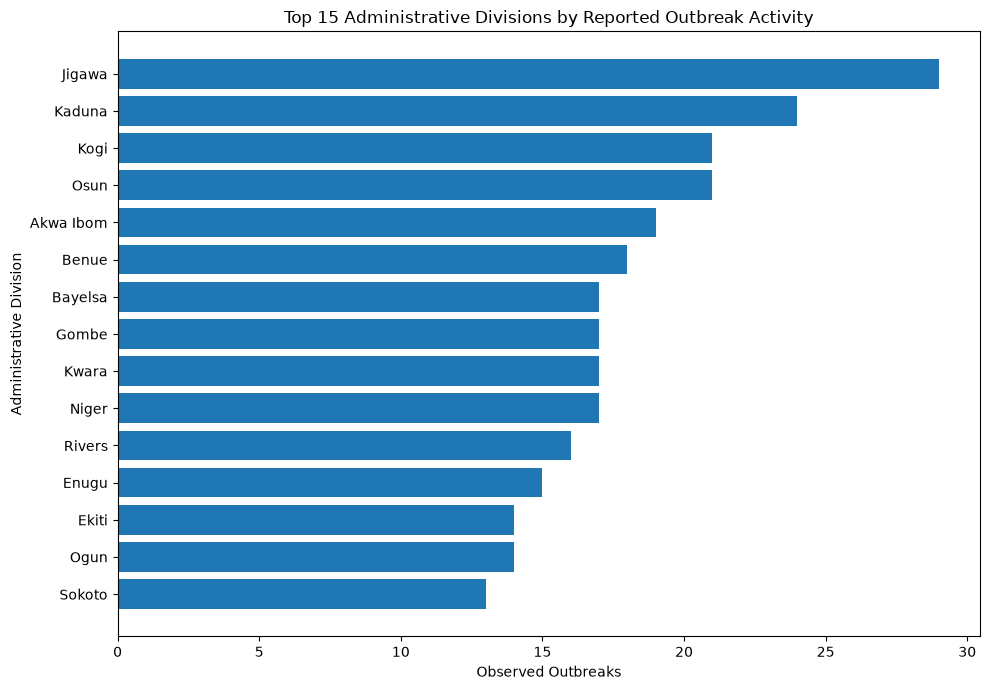

GEOGRAPHIC DISTRIBUTION VISUALISATION: PASSED


In [11]:
# ============================================================
# 7.2 GEOGRAPHIC DISTRIBUTION
# ============================================================

top_15_states = (
    state_totals
    .head(15)
    .sort_values("observed_outbreaks", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_states["administrative_division"],
    top_15_states["observed_outbreaks"]
)

plt.title("Top 15 Administrative Divisions by Reported Outbreak Activity")
plt.xlabel("Observed Outbreaks")
plt.ylabel("Administrative Division")

plt.tight_layout()
plt.show()

print("GEOGRAPHIC DISTRIBUTION VISUALISATION: PASSED")

## 7.3 Temporal–Geographic Distribution of Reported Outbreak Activity

This heatmap shows reported outbreak activity across administrative
divisions and years.

Only the 15 administrative divisions with the highest total observed
outbreak activity are displayed to maintain readability.

The figure is descriptive and reflects recorded surveillance activity.
Differences between administrative divisions may be influenced by
reporting coverage, surveillance intensity and data availability.

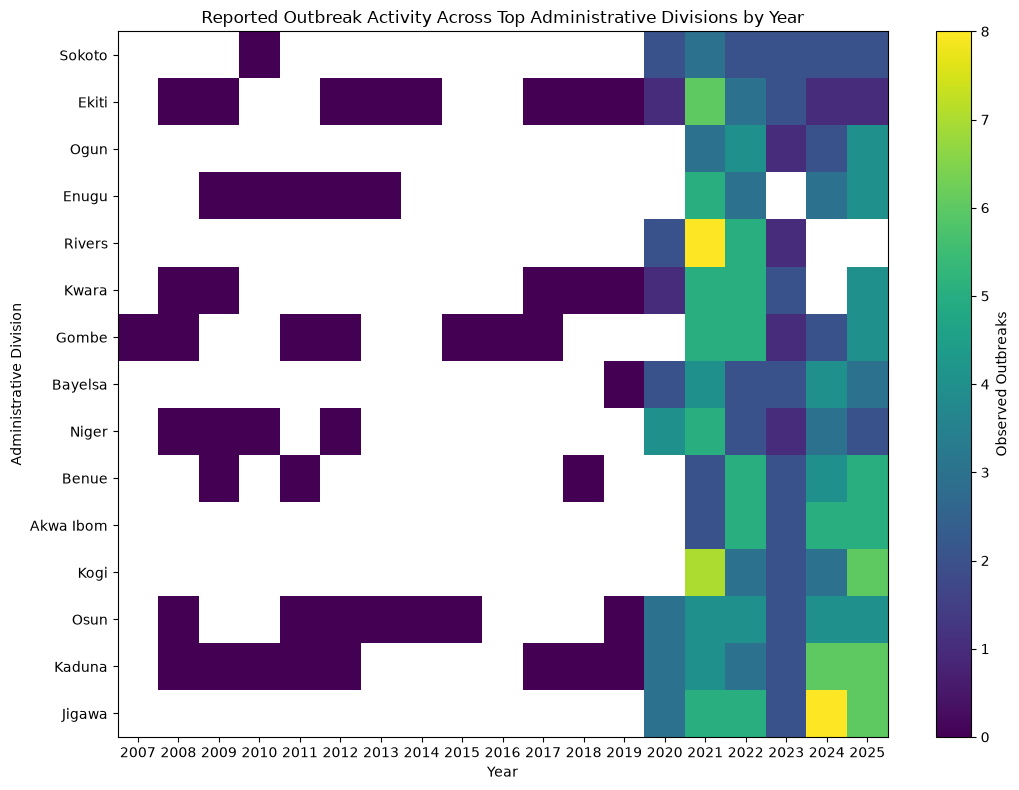

TEMPORAL-GEOGRAPHIC HEATMAP: PASSED


In [13]:
# ============================================================
# 7.3 TEMPORAL-GEOGRAPHIC HEATMAP
# ============================================================

# Select the 15 most active administrative divisions
top_15_divisions = (
    state_totals
    .head(15)["administrative_division"]
    .tolist()
)

heatmap_data = (
    state_year_activity[
        state_year_activity["administrative_division"]
        .isin(top_15_divisions)
    ]
    .pivot(
        index="administrative_division",
        columns="year",
        values="observed_outbreaks"
    )
)

# Order divisions by total observed activity
heatmap_data = heatmap_data.loc[
    heatmap_data.sum(axis=1).sort_values().index
]

# Convert to masked array so missing state-year observations
# are visually separated from genuine zero values.
heatmap_masked = np.ma.masked_invalid(
    heatmap_data.values.astype(float)
)

plt.figure(figsize=(11, 8))

cmap = plt.cm.viridis.copy()
cmap.set_bad("white")

plt.imshow(
    heatmap_masked,
    aspect="auto",
    cmap=cmap
)

plt.colorbar(
    label="Observed Outbreaks"
)

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title(
    "Reported Outbreak Activity Across Top Administrative Divisions by Year"
)

plt.xlabel("Year")
plt.ylabel("Administrative Division")

plt.tight_layout()
plt.show()

print("TEMPORAL-GEOGRAPHIC HEATMAP: PASSED")

## 8. Integrated Interpretation

The combined modelling, explainability and geographic analyses provide
three main findings.

First, recent outbreak history is the strongest predictor of the
modelled outbreak count. The previous-semester outbreak count and
rolling outbreak-history features consistently contribute more to model
performance than most climate and calendar variables. This indicates
that temporal persistence in reported outbreak activity is an important
signal for the early-warning task.

Second, the model demonstrates moderate predictive performance under
strict chronological out-of-sample validation. The pooled out-of-sample
MAE is approximately 6.42 outbreaks, while the mean fold MAE is
approximately 6.52 outbreaks. Performance varies across validation
periods, and larger outbreak counts are associated with larger absolute
prediction errors.

Third, the administrative analysis shows that reported outbreak activity
is not distributed uniformly across the country. Some administrative
divisions account for substantially more recorded activity than others,
and the temporal-geographic heatmap shows that the availability and
intensity of recorded activity vary across both locations and years.

These findings support the use of the model as a decision-support
component for prioritising surveillance attention and further
investigation. They do not establish causal relationships between
climate variables and disease occurrence, nor do they establish
underlying disease prevalence or individual farm-level disease risk.

## 9. Limitations

Several limitations should be considered when interpreting the results.

### 9.1 Surveillance and reporting bias

The modelling target is derived from reported outbreak records.
Observed activity therefore depends on disease detection, reporting
coverage and surveillance practices. Areas or periods with fewer records
may reflect limited reporting rather than genuinely lower disease
occurrence.

### 9.2 Temporal coverage

The model relies on historical observations available in the analytical
dataset. Changes in reporting practices, surveillance intensity and
data completeness over time may affect temporal comparisons.

### 9.3 Geographic interpretation

Administrative-level activity represents recorded surveillance activity
and should not be interpreted directly as disease prevalence or
geographic disease risk.

### 9.4 Prediction error

The model has moderate out-of-sample performance and shows a tendency
towards overprediction in the evaluated observations. Prediction errors
also increase with outbreak magnitude, indicating that larger outbreak
events remain more difficult to estimate accurately.

### 9.5 Feature interpretation

Feature importance identifies variables that contribute to predictive
performance within the fitted model. It does not demonstrate that a
feature causes outbreaks. In particular, the strong contribution of
historical outbreak variables should be interpreted as evidence of
predictive temporal dependence rather than causal persistence.

### 9.6 Operational use

The model should not be used as a diagnostic system or as a replacement
for veterinary investigation, laboratory confirmation, field
surveillance or official disease-control procedures. Its appropriate
role is as an early-warning and decision-support component.

## 10. Conclusion

This project developed and evaluated a machine-learning-based early
warning framework for forecasting reported poultry disease outbreak
counts in Nigeria.

The final Random Forest model was selected through rolling-origin
temporal validation and evaluated on eight chronological validation
folds. The formal out-of-sample evaluation produced a pooled MAE of
6.42 outbreaks and a pooled RMSE of 13.21 outbreaks, with a mean fold
MAE of 6.52 outbreaks.

Model explainability analysis indicates that recent outbreak history is
the dominant predictive signal, while selected climate variables provide
additional but comparatively smaller contributions. Historical
administrative analysis further demonstrates substantial variation in
reported outbreak activity across locations and time.

The resulting model and production artefacts provide a reproducible
foundation for an early-warning decision-support system. However, the
system should be interpreted within the limitations of surveillance
data and should complement, rather than replace, veterinary
surveillance, field investigation and laboratory confirmation.

Future development should focus on improving data completeness,
incorporating additional epidemiological and environmental signals,
validating predictions prospectively, and evaluating the system with
domain experts and operational surveillance stakeholders.

In [18]:
# ============================================================
# IDENTIFY MISSING NOTEBOOK 10 AUDIT ARTEFACT
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

required_files = {
    "final_model": (
        PROJECT_ROOT
        / "artifacts"
        / "final_model"
        / "random_forest_pipeline.joblib"
    ),

    "metadata": (
        PROJECT_ROOT
        / "artifacts"
        / "final_model"
        / "model_metadata.json"
    ),

    "schema": (
        PROJECT_ROOT
        / "artifacts"
        / "final_model"
        / "production_schema.json"
    ),

    "evaluation_summary": (
        PROJECT_ROOT
        / "artifacts"
        / "evaluation"
        / "evaluation_summary.json"
    ),

    "fold_metrics": (
        PROJECT_ROOT
        / "artifacts"
        / "evaluation"
        / "fold_metrics.csv"
    ),

    "oos_predictions": (
        PROJECT_ROOT
        / "artifacts"
        / "evaluation"
        / "oos_predictions.csv"
    ),

    "feature_importance": (
        PROJECT_ROOT
        / "artifacts"
        / "evaluation"
        / "feature_importance.csv"
    ),

    "permutation_importance": (
        PROJECT_ROOT
        / "artifacts"
        / "evaluation"
        / "oos_permutation_importance.csv"
    ),

    "administrative_data": (
        PROJECT_ROOT
        / "data"
        / "processed"
        / "wahis_analytical_table.csv"
    )
}

print("=" * 70)
print("NOTEBOOK 10 — ARTEFACT AVAILABILITY CHECK")
print("=" * 70)

print("\nPROJECT ROOT:")
print(PROJECT_ROOT)

print("\nEXPECTED FILES:")

missing = []

for name, path in required_files.items():
    exists = path.is_file()

    print(f"\n{name}")
    print(f"  Path:   {path}")
    print(f"  Exists: {exists}")

    if not exists:
        missing.append(name)

print("\n" + "=" * 70)

if missing:
    print("MISSING ARTEFACTS:")
    for name in missing:
        print(f"  - {name}")
else:
    print("ALL EXPECTED ARTEFACTS FOUND")

print("=" * 70)

NOTEBOOK 10 — ARTEFACT AVAILABILITY CHECK

PROJECT ROOT:
c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria

EXPECTED FILES:

final_model
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\final_model\random_forest_pipeline.joblib
  Exists: True

metadata
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\final_model\model_metadata.json
  Exists: True

schema
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\final_model\production_schema.json
  Exists: True

evaluation_summary
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\evaluation_summary.json
  Exists: False

fold_metrics
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\fold_metrics.csv
  Exists: False

oos_predictions
  Path:   c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation\oo

In [19]:
# ============================================================
# INSPECT EVALUATION ARTEFACT DIRECTORY
# ============================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
EVALUATION_DIR = PROJECT_ROOT / "artifacts" / "evaluation"

print("=" * 70)
print("EVALUATION ARTEFACT DIRECTORY")
print("=" * 70)

print("\nDirectory:")
print(EVALUATION_DIR)

print("\nExists:", EVALUATION_DIR.exists())
print("Is directory:", EVALUATION_DIR.is_dir())

if EVALUATION_DIR.exists() and EVALUATION_DIR.is_dir():

    files = sorted(
        [p for p in EVALUATION_DIR.iterdir() if p.is_file()]
    )

    print(f"\nFiles found: {len(files)}")

    for file in files:
        print(f" - {file.name}")

else:
    print("\nThe evaluation directory does not exist.")

print("\n" + "=" * 70)

EVALUATION ARTEFACT DIRECTORY

Directory:
c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria\artifacts\evaluation

Exists: True
Is directory: True

Files found: 7
 - model_evaluation_dataset.csv
 - random_forest_feature_importance.csv
 - random_forest_oos_permutation_importance.csv
 - rolling_origin_evaluation_summary.json
 - rolling_origin_fold_metrics.csv
 - rolling_origin_oos_predictions.csv
 - temporal_period_values.csv



In [21]:
# ============================================================
# INSPECT SAVED MODEL METADATA AND SCHEMA
# ============================================================

from pathlib import Path
import json

PROJECT_ROOT = Path.cwd().parent

metadata_path = (
    PROJECT_ROOT
    / "artifacts"
    / "final_model"
    / "model_metadata.json"
)

schema_path = (
    PROJECT_ROOT
    / "artifacts"
    / "final_model"
    / "production_schema.json"
)

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

with open(schema_path, "r", encoding="utf-8") as f:
    schema = json.load(f)

print("=" * 70)
print("MODEL METADATA")
print("=" * 70)

print("\nMetadata keys:")
for key in metadata.keys():
    print(f" - {key}")

print("\nMetadata:")
print(json.dumps(metadata, indent=2))

print("\n" + "=" * 70)
print("PRODUCTION SCHEMA")
print("=" * 70)

print("\nSchema keys:")
for key in schema.keys():
    print(f" - {key}")

print("\nSchema:")
print(json.dumps(schema, indent=2))

print("\n" + "=" * 70)

MODEL METADATA

Metadata keys:
 - model_name
 - model_type
 - model_version
 - target_column
 - n_training_records
 - n_features
 - features
 - training_period
 - validation
 - training_diagnostics
 - prediction_sanity_check
 - random_forest_parameters
 - created_at_utc

Metadata:
{
  "model_name": "Random Forest",
  "model_type": "RandomForestRegressor",
  "model_version": "1.0.0",
  "target_column": "target_outbreak_count",
  "n_training_records": 445,
  "n_features": 27,
  "features": [
    "year",
    "semester_order",
    "is_first_semester",
    "is_second_semester",
    "semester_sin",
    "semester_cos",
    "years_since_2019",
    "year_sin",
    "year_cos",
    "has_adm1",
    "is_country_level",
    "disease_code",
    "previous_semester_outbreak_count",
    "two_semesters_prior_outbreak_count",
    "outbreak_history_mean_3",
    "outbreak_history_max_3",
    "climate_available",
    "temperature_missing",
    "dewpoint_missing",
    "precipitation_missing",
    "wind_missin

In [23]:
# ============================================================
# INSPECT SAVED EVALUATION SUMMARY
# ============================================================

from pathlib import Path
import json

PROJECT_ROOT = Path.cwd().parent

evaluation_path = (
    PROJECT_ROOT
    / "artifacts"
    / "evaluation"
    / "rolling_origin_evaluation_summary.json"
)

with open(
    evaluation_path,
    "r",
    encoding="utf-8"
) as f:
    evaluation_summary = json.load(f)

print("=" * 70)
print("SAVED EVALUATION SUMMARY")
print("=" * 70)

print("\nKeys:")
for key in evaluation_summary.keys():
    print(f" - {key}")

print("\nFull contents:")
print(json.dumps(
    evaluation_summary,
    indent=2
))

print("\n" + "=" * 70)

SAVED EVALUATION SUMMARY

Keys:
 - evaluation_method
 - validation_folds
 - out_of_sample_predictions
 - validation_periods
 - mean_fold_mae
 - std_fold_mae
 - mean_fold_rmse
 - std_fold_rmse
 - mean_fold_median_absolute_error
 - pooled_mae
 - pooled_rmse
 - pooled_median_absolute_error

Full contents:
{
  "evaluation_method": "rolling_origin_temporal_validation",
  "validation_folds": 8,
  "out_of_sample_predictions": 302,
  "validation_periods": [
    4044,
    4045,
    4046,
    4047,
    4048,
    4049,
    4050,
    4051
  ],
  "mean_fold_mae": 6.515275851272092,
  "std_fold_mae": 1.4938928511753018,
  "mean_fold_rmse": 11.594073626101732,
  "std_fold_rmse": 4.828319221470369,
  "mean_fold_median_absolute_error": 3.337083333333333,
  "pooled_mae": 6.415011037527593,
  "pooled_rmse": 13.20678935203263,
  "pooled_median_absolute_error": 3.2183333333333333
}



In [25]:
# ============================================================
# INSPECT OOS PREDICTION COLUMNS
# ============================================================

print("=" * 70)
print("OOS PREDICTION DATASET STRUCTURE")
print("=" * 70)

print("\nColumns:")
for i, column in enumerate(oos_predictions.columns, start=1):
    print(f"{i}. {column}")

print("\nShape:")
print(oos_predictions.shape)

print("\nFirst 5 rows:")
display(oos_predictions.head())

print("\nData types:")
print(oos_predictions.dtypes)

print("\n" + "=" * 70)

OOS PREDICTION DATASET STRUCTURE

Columns:
1. temporal_period
2. target_outbreak_count
3. fold
4. predicted_outbreak_count

Shape:
(302, 4)

First 5 rows:


,temporal_period,target_outbreak_count,fold,predicted_outbreak_count
0,4044,1.0,1,1.323333
1,4044,83.0,1,95.790000
2,4044,4.0,1,1.790000
3,4044,2.0,1,11.756667
4,4044,5.0,1,3.586667



Data types:
temporal_period               int64
target_outbreak_count       float64
fold                          int64
predicted_outbreak_count    float64
dtype: object



In [26]:
# ============================================================
# NOTEBOOK 10 — FINAL INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

print("=" * 70)
print("NOTEBOOK 10 — FINAL INTEGRITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().parent

assert PROJECT_ROOT.name == "poultry-disease-early-warning-nigeria"

print("\nProject root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# 2. Required artefacts
# ------------------------------------------------------------

required_files = {
    "final_model":
        PROJECT_ROOT / "artifacts" / "final_model"
        / "random_forest_pipeline.joblib",

    "metadata":
        PROJECT_ROOT / "artifacts" / "final_model"
        / "model_metadata.json",

    "schema":
        PROJECT_ROOT / "artifacts" / "final_model"
        / "production_schema.json",

    "evaluation_summary":
        PROJECT_ROOT / "artifacts" / "evaluation"
        / "rolling_origin_evaluation_summary.json",

    "fold_metrics":
        PROJECT_ROOT / "artifacts" / "evaluation"
        / "rolling_origin_fold_metrics.csv",

    "oos_predictions":
        PROJECT_ROOT / "artifacts" / "evaluation"
        / "rolling_origin_oos_predictions.csv",

    "feature_importance":
        PROJECT_ROOT / "artifacts" / "evaluation"
        / "random_forest_feature_importance.csv",

    "permutation_importance":
        PROJECT_ROOT / "artifacts" / "evaluation"
        / "random_forest_oos_permutation_importance.csv",

    "administrative_data":
        PROJECT_ROOT / "data" / "processed"
        / "wahis_analytical_table.csv"
}

print("\nRequired artefacts:")

for name, path in required_files.items():
    print(f"{name:25s}: {path.exists()}")

assert all(
    path.is_file()
    for path in required_files.values()
)

print("\nAll required artefacts exist.")

# ------------------------------------------------------------
# 3. Load artefacts
# ------------------------------------------------------------

final_model = joblib.load(
    required_files["final_model"]
)

with open(
    required_files["metadata"],
    "r",
    encoding="utf-8"
) as f:
    metadata = json.load(f)

with open(
    required_files["schema"],
    "r",
    encoding="utf-8"
) as f:
    schema = json.load(f)

with open(
    required_files["evaluation_summary"],
    "r",
    encoding="utf-8"
) as f:
    evaluation_summary = json.load(f)

fold_metrics = pd.read_csv(
    required_files["fold_metrics"]
)

oos_predictions = pd.read_csv(
    required_files["oos_predictions"]
)

feature_importance = pd.read_csv(
    required_files["feature_importance"]
)

permutation_importance = pd.read_csv(
    required_files["permutation_importance"]
)

administrative_data = pd.read_csv(
    required_files["administrative_data"]
)

print("\nArtefacts loaded successfully.")

# ------------------------------------------------------------
# 4. Model integrity
# ------------------------------------------------------------

assert hasattr(final_model, "predict")

assert metadata["model_type"] == "RandomForestRegressor"

assert (
    metadata["n_features"]
    == len(metadata["features"])
)

assert (
    schema["features"]["count"]
    == len(schema["features"]["ordered_names"])
)

assert (
    metadata["features"]
    == schema["features"]["ordered_names"]
)

assert (
    metadata["n_training_records"]
    == schema["training"]["records"]
)

print("\nMODEL INTEGRITY: PASSED")

print(
    f"  Model type: {metadata['model_type']}"
)

print(
    f"  Features: {metadata['n_features']}"
)

print(
    f"  Training records: "
    f"{metadata['n_training_records']}"
)

# ------------------------------------------------------------
# 5. Evaluation integrity
# ------------------------------------------------------------

assert (
    evaluation_summary["evaluation_method"]
    == "rolling_origin_temporal_validation"
)

assert (
    evaluation_summary["validation_folds"]
    == 8
)

assert (
    evaluation_summary["out_of_sample_predictions"]
    == 302
)

assert np.isclose(
    evaluation_summary["pooled_mae"],
    6.415011037527593
)

assert np.isclose(
    evaluation_summary["pooled_rmse"],
    13.20678935203263
)

assert np.isclose(
    evaluation_summary["mean_fold_mae"],
    6.515275851272092
)

assert np.isclose(
    evaluation_summary["mean_fold_rmse"],
    11.594073626101732
)

assert len(fold_metrics) == 8

assert len(oos_predictions) == 302

assert (
    len(feature_importance)
    == metadata["n_features"]
)

assert (
    len(permutation_importance)
    == metadata["n_features"]
)

print("\nEVALUATION INTEGRITY: PASSED")

print(
    f"  Method: "
    f"{evaluation_summary['evaluation_method']}"
)

print(
    f"  Validation folds: "
    f"{evaluation_summary['validation_folds']}"
)

print(
    f"  OOS predictions: "
    f"{evaluation_summary['out_of_sample_predictions']}"
)

print(
    f"  Pooled MAE: "
    f"{evaluation_summary['pooled_mae']:.3f}"
)

print(
    f"  Pooled RMSE: "
    f"{evaluation_summary['pooled_rmse']:.3f}"
)

print(
    f"  Mean fold MAE: "
    f"{evaluation_summary['mean_fold_mae']:.3f}"
)

print(
    f"  Mean fold RMSE: "
    f"{evaluation_summary['mean_fold_rmse']:.3f}"
)

# ------------------------------------------------------------
# 6. OOS prediction integrity
# ------------------------------------------------------------

required_oos_columns = [
    "temporal_period",
    "target_outbreak_count",
    "fold",
    "predicted_outbreak_count"
]

for column in required_oos_columns:
    assert column in oos_predictions.columns

assert (
    oos_predictions["target_outbreak_count"]
    .notna()
    .all()
)

assert (
    oos_predictions["predicted_outbreak_count"]
    .notna()
    .all()
)

assert np.isfinite(
    oos_predictions["target_outbreak_count"]
).all()

assert np.isfinite(
    oos_predictions["predicted_outbreak_count"]
).all()

assert (
    oos_predictions["predicted_outbreak_count"]
    >= 0
).all()

assert (
    oos_predictions["fold"]
    .nunique()
    == 8
)

assert (
    oos_predictions["temporal_period"]
    .nunique()
    == 8
)

print("\nOOS PREDICTION INTEGRITY: PASSED")

print(
    f"  Records: {len(oos_predictions)}"
)

print(
    "  Required columns: PASSED"
)

print(
    "  Actual target values: finite"
)

print(
    "  Predictions: finite and non-negative"
)

print(
    f"  Validation folds represented: "
    f"{oos_predictions['fold'].nunique()}"
)

print(
    f"  Validation periods represented: "
    f"{oos_predictions['temporal_period'].nunique()}"
)

# ------------------------------------------------------------
# 7. Geographic data integrity
# ------------------------------------------------------------

required_geo_columns = [
    "year",
    "administrative_division",
    "outbreak_count_observed",
    "new_outbreaks"
]

for column in required_geo_columns:
    assert column in administrative_data.columns

assert len(administrative_data) > 0

print("\nGEOGRAPHIC DATA INTEGRITY: PASSED")

print(
    f"  Records: {len(administrative_data)}"
)

print(
    "  Administrative divisions: "
    f"{administrative_data['administrative_division'].nunique()}"
)

# ------------------------------------------------------------
# 8. Production schema consistency
# ------------------------------------------------------------

schema_mean_mae = (
    schema["validation"]["mean_mae"]
)

schema_mean_rmse = (
    schema["validation"]["mean_rmse"]
)

evaluation_mean_mae = (
    evaluation_summary["mean_fold_mae"]
)

evaluation_mean_rmse = (
    evaluation_summary["mean_fold_rmse"]
)

schema_mae_matches = np.isclose(
    schema_mean_mae,
    evaluation_mean_mae
)

schema_rmse_matches = np.isclose(
    schema_mean_rmse,
    evaluation_mean_rmse
)

print("\nPRODUCTION SCHEMA CONSISTENCY:")

print(
    f"  Schema mean MAE: "
    f"{schema_mean_mae:.6f}"
)

print(
    f"  Evaluation mean MAE: "
    f"{evaluation_mean_mae:.6f}"
)

print(
    f"  MAE matches: "
    f"{schema_mae_matches}"
)

print(
    f"  Schema mean RMSE: "
    f"{schema_mean_rmse:.6f}"
)

print(
    f"  Evaluation mean RMSE: "
    f"{evaluation_mean_rmse:.6f}"
)

print(
    f"  RMSE matches: "
    f"{schema_rmse_matches}"
)

# ------------------------------------------------------------
# 9. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)

if schema_mae_matches and schema_rmse_matches:

    print(
        "NOTEBOOK 10 FINAL INTEGRITY AUDIT: PASSED"
    )

else:

    print(
        "NOTEBOOK 10 FINAL INTEGRITY AUDIT: "
        "PASSED WITH SCHEMA CONSISTENCY WARNING"
    )

    print(
        "\nThe model and evaluation artefacts are valid."
    )

    print(
        "Only the validation summary values stored in "
        "production_schema.json require synchronisation."
    )

print("=" * 70)

NOTEBOOK 10 — FINAL INTEGRITY AUDIT

Project root:
c:\Users\TECHGROW ANALYTICS\poultry-disease-early-warning-nigeria

Required artefacts:
final_model              : True
metadata                 : True
schema                   : True
evaluation_summary       : True
fold_metrics             : True
oos_predictions          : True
feature_importance       : True
permutation_importance   : True
administrative_data      : True

All required artefacts exist.

Artefacts loaded successfully.

MODEL INTEGRITY: PASSED
  Model type: RandomForestRegressor
  Features: 27
  Training records: 445

EVALUATION INTEGRITY: PASSED
  Method: rolling_origin_temporal_validation
  Validation folds: 8
  OOS predictions: 302
  Pooled MAE: 6.415
  Pooled RMSE: 13.207
  Mean fold MAE: 6.515
  Mean fold RMSE: 11.594

OOS PREDICTION INTEGRITY: PASSED
  Records: 302
  Required columns: PASSED
  Actual target values: finite
  Predictions: finite and non-negative
  Validation folds represented: 8
  Validation periods 